# Model training

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor 

from scipy import stats

from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, roc_curve, RocCurveDisplay, classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay, make_scorer

import joblib

# needed for the pipeline transformer
import sys
sys.path.append(str(Path().cwd().parents[0] / "src"))
from components.transformations import calculate_deviations

from training.mlflow_utils import configure_mlflow
import mlflow
configure_mlflow()

In [2]:
data_location = Path().cwd().parent / "data"

In [3]:
df = pd.read_csv(data_location / "baseline_data.csv")
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [4]:
# creating the baseline dataset
X = df.drop(["id", "diagnosis"], axis=1)
y_raw = df.loc[:, "diagnosis"]

In [5]:
y_raw.unique()

<ArrowStringArray>
['M', 'B']
Length: 2, dtype: str

In [6]:
# splitting the data
# raw = uses labels as B and M
X_train, X_test, y_train_raw, y_test_raw = train_test_split(X, y_raw, test_size=0.2, stratify=y_raw, shuffle=True)#, random_state=42)

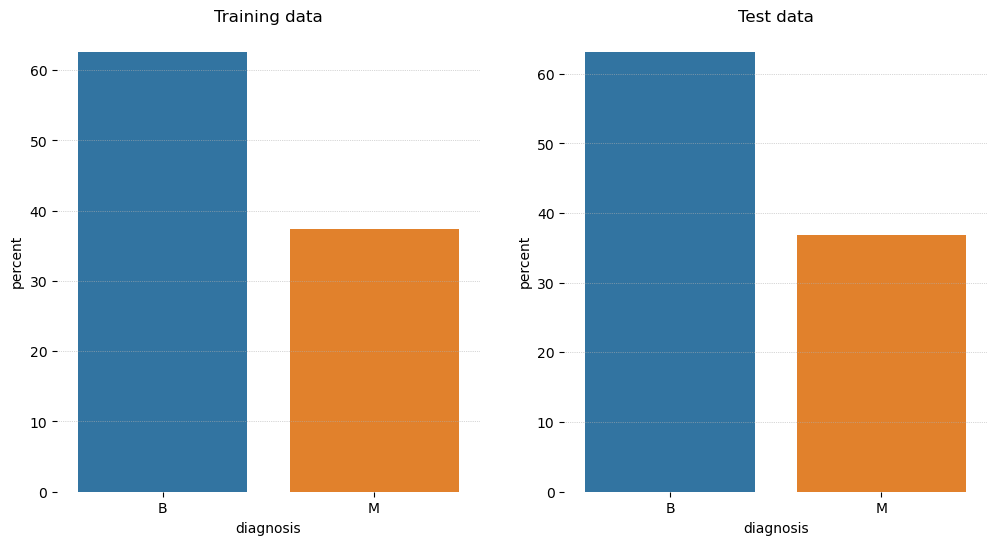

In [7]:
fig, axs = plt.subplots(figsize=(12,6), nrows=1, ncols=2)
sns.countplot(x=y_train_raw.sort_values(), stat="percent", hue=y_train_raw.sort_values(), ax=axs[0])
axs[0].set_title("Training data")
sns.countplot(x=y_test_raw.sort_values(),  stat="percent", hue=y_test_raw.sort_values(),  ax=axs[1])
axs[1].set_title("Test data")
for ax in axs:
    ax.spines[["top", "right", "bottom", "left"]].set_visible(False)
    ax.grid(True, linewidth=0.5, linestyle=':', axis="y")

In [8]:
print(X_train.shape)
print(X_test.shape)

(455, 30)
(114, 30)


In [9]:
# encode labels
label_encoder = LabelEncoder()
y_train = pd.Series(label_encoder.fit_transform(y_train_raw), index=y_train_raw.index, name="y_train").astype(float)
y_test = pd.Series(label_encoder.transform(y_test_raw), index=y_test_raw.index, name="y_test").astype(float)

In [10]:
# labels
labels = dict(
    zip(
        label_encoder.classes_,
        label_encoder.transform(label_encoder.classes_)
    )
)
labels

{'B': np.int64(0), 'M': np.int64(1)}

In [11]:
# create dataset for mlflow
training_dataset = mlflow.data.from_pandas(
    pd.merge(X_train, y_train, left_index=True, right_index=True),
    name="X_train",
    targets="y_train"
)

test_dataset = mlflow.data.from_pandas(
    pd.merge(X_test, y_test, left_index=True, right_index=True),
    name="X_test",
    targets="y_test"
)

# Baselines

The following models are investigated as baselines for the task.  
Keeping all features in the dataset, what are the most promising models regarding performance and interpretability?

In [12]:
def run_pipeline(X, y, model, return_scores=False):

    # cross validation strategy
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    
    model_name, model_type = model
    
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        (model_name, model_type)
    ])

    if hasattr(model_type, "predict_proba"):
        method = "predict_proba"
        cv_scores = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba", n_jobs=-1, verbose=3)
        y_pred = cv_scores.argmax(axis=1)

        if return_scores:
            return cv_scores[:,1], y_pred

        return {
        "model"     : model_name,
        "method"    : method,
        "precision" : precision_score(y_pred=y_pred, y_true=y),
        "recall"    : recall_score(y_pred=y_pred, y_true=y),
        "f1_score"  : f1_score(y_pred=y_pred, y_true=y),
        "roc_auc"   : roc_auc_score(y_true=y, y_score=cv_scores[:,1])
    }
        
    else:
        # All methods investigatated have a predict_proba method
        # in case a new model with a decision_function method is added
        # This must be updated
        method = "decision_function"
        cv_scores = cross_val_predict(pipe, X, y, cv=cv, method="decision_function", n_jobs=-1, verbose=3)

        return {
        "model"     : model_name,
        "method"    : method,
        "precision" : np.nan,
        "recall"    : np.nan,
        "f1_score"  : np.nan,
        "roc_auc"   : np.nan
    }

    

In [13]:
# Baseline models with some defalut parameters
models = [
    ("logistic_regression", LogisticRegression(solver="liblinear", l1_ratio=1, C=1, max_iter=1000)),
    ("knn", KNeighborsClassifier(n_neighbors=5, metric="euclidean")),
    ("decision_tree", DecisionTreeClassifier(criterion="entropy", max_depth=4, splitter="best")),
    ("forest", RandomForestClassifier(n_estimators=100, criterion="entropy")),
    ("gradient_boosting", GradientBoostingClassifier()),
    ("adaboost", AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=4), n_estimators=100)),
    ("support_vector", CalibratedClassifierCV(SVC(C=0.5, kernel="rbf", gamma="auto"), ensemble=False)), # avoid sklearn warning
    ("gaussian_nb", GaussianNB()),
    ("mlp", MLPClassifier(hidden_layer_sizes=(50,50), activation="relu", early_stopping=True, batch_size=64))
]

In [14]:
with mlflow.start_run(run_name="Baselines") as run:

    # log the original data
    mlflow.log_artifact(data_location.joinpath("baseline_data.csv"), artifact_path="datasets")
    # log trainig dataset
    mlflow.log_input(training_dataset, context="training")
        
    scores_baseline = []
    for model_name, estimator in models:
        with mlflow.start_run(run_name=f"{model_name}_baseline", nested=True):
            # get data and scores for experiments
            score = run_pipeline(X_train, y_train, (model_name, estimator))
            
            # log the parameters of the model
            mlflow.log_params(estimator.get_params())
            
            # log metrics - they all must be numbers
            metrics = {
                f"{key}" : value for key, value in score.items()
                if key not in ("model", "method")
            }
            mlflow.log_metrics(metrics)

            mlflow.set_tag("evaluation_method", score["method"])
            
            # append all data for creating the dataframe with all scores
            scores_baseline.append(score)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    1.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.


🏃 View run logistic_regression_baseline at: http://127.0.0.1:5000/#/experiments/1/runs/8a23d0e6a50646e5a71b870d355dbd16
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.7s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.


🏃 View run knn_baseline at: http://127.0.0.1:5000/#/experiments/1/runs/480ca485d81b413a9efa77c33ecddbce
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.8s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.


🏃 View run decision_tree_baseline at: http://127.0.0.1:5000/#/experiments/1/runs/10f18a9285e6425591c0641cf0b641ef
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


... (3 outputs left out)

🏃 View run adaboost_baseline at: http://127.0.0.1:5000/#/experiments/1/runs/cdb3dab25ec549a18db5f5ee68876921
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.7s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.


🏃 View run support_vector_baseline at: http://127.0.0.1:5000/#/experiments/1/runs/81df857406d9462984051d5ee209e2db
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run gaussian_nb_baseline at: http://127.0.0.1:5000/#/experiments/1/runs/652931f27b124cb48d717bb305fa2259
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp_baseline at: http://127.0.0.1:5000/#/experiments/1/runs/ff8959cf16984dce87fe2b633b19ef30
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run Baselines at: http://127.0.0.1:5000/#/experiments/1/runs/6dbb3231d7c146ae8305c98d0af574a1
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.6s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished


## Baseline metrics

In [15]:
# Using all features, Logistic Regression, support vector machines and KNN seem to be the most promesing models
# They already achieve high performance but interprertability is difficult
metrics_baseline = pd.DataFrame(scores_baseline).sort_values("f1_score", ascending=False, ignore_index=True)
metrics_baseline

,model,method,precision,recall,f1_score,roc_auc
0,logistic_regression,predict_proba,0.964497,0.958824,0.961652,0.993106
1,knn,predict_proba,0.975460,0.935294,0.954955,0.976687
2,support_vector,predict_proba,0.952663,0.947059,0.949853,0.993148
3,forest,predict_proba,0.951220,0.917647,0.934132,0.990351
4,gradient_boosting,predict_proba,0.920000,0.947059,0.933333,0.991961
5,adaboost,predict_proba,0.924855,0.941176,0.932945,0.987626
6,mlp,predict_proba,0.974194,0.888235,0.929231,0.982147
7,gaussian_nb,predict_proba,0.933735,0.911765,0.922619,0.982921
8,decision_tree,predict_proba,0.907514,0.923529,0.915452,0.956140


# Feature selection

## Welch's test (ANOVA)
Since we are dealing with only two features, we can use a Welch's test instead of ANOVA to see whether there are any differences between the benign and maligant tumors for each feature.

In [16]:
# merge the data again to use the label for grouping
X_for_feature_selection = pd.merge(X_train, y_train, left_index=True, right_index=True)
X_for_feature_selection.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,y_train
115,11.93,21.53,76.53,438.6,0.09768,0.07849,0.03328,0.02008,0.1688,0.06194,...,26.15,87.54,583.0,0.15000,0.23990,0.15030,0.07247,0.2438,0.08541,0.0
191,12.77,21.41,82.02,507.4,0.08749,0.06601,0.03112,0.02864,0.1694,0.06287,...,23.50,89.04,579.5,0.09388,0.08978,0.05186,0.04773,0.2179,0.06871,0.0
481,13.90,19.24,88.73,602.9,0.07991,0.05326,0.02995,0.02070,0.1579,0.05594,...,26.42,104.40,830.5,0.10640,0.14150,0.16730,0.08150,0.2356,0.07603,0.0
429,12.72,17.67,80.98,501.3,0.07896,0.04522,0.01402,0.01835,0.1459,0.05544,...,20.96,88.87,586.8,0.10680,0.09605,0.03469,0.03612,0.2165,0.06025,0.0
271,11.29,13.04,72.23,388.0,0.09834,0.07608,0.03265,0.02755,0.1769,0.06270,...,16.18,78.27,457.5,0.13580,0.15070,0.12750,0.08750,0.2733,0.08022,0.0


In [17]:
# separte into two groups B and M
benign    = X_for_feature_selection[X_for_feature_selection["y_train"] == 0]
malignant = X_for_feature_selection[X_for_feature_selection["y_train"] == 1] # This is the positive class what we want to detect

In [18]:
display(benign.head())
display(malignant.head())

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,y_train
115,11.93,21.53,76.53,438.6,0.09768,0.07849,0.03328,0.02008,0.1688,0.06194,...,26.15,87.54,583.0,0.15000,0.23990,0.15030,0.07247,0.2438,0.08541,0.0
191,12.77,21.41,82.02,507.4,0.08749,0.06601,0.03112,0.02864,0.1694,0.06287,...,23.50,89.04,579.5,0.09388,0.08978,0.05186,0.04773,0.2179,0.06871,0.0
481,13.90,19.24,88.73,602.9,0.07991,0.05326,0.02995,0.02070,0.1579,0.05594,...,26.42,104.40,830.5,0.10640,0.14150,0.16730,0.08150,0.2356,0.07603,0.0
429,12.72,17.67,80.98,501.3,0.07896,0.04522,0.01402,0.01835,0.1459,0.05544,...,20.96,88.87,586.8,0.10680,0.09605,0.03469,0.03612,0.2165,0.06025,0.0
271,11.29,13.04,72.23,388.0,0.09834,0.07608,0.03265,0.02755,0.1769,0.06270,...,16.18,78.27,457.5,0.13580,0.15070,0.12750,0.08750,0.2733,0.08022,0.0


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,y_train
8,13.00,21.82,87.5,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,0.07389,...,30.73,106.2,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720,1.0
274,17.93,24.48,115.2,998.9,0.08855,0.07027,0.05699,0.04744,0.1538,0.05510,...,34.69,135.1,1320.0,0.1315,0.1806,0.2080,0.1136,0.2504,0.07948,1.0
39,13.48,20.82,88.4,559.2,0.10160,0.12550,0.10630,0.05439,0.1720,0.06419,...,26.02,107.3,740.4,0.1610,0.4225,0.5030,0.2258,0.2807,0.10710,1.0
78,20.18,23.97,143.7,1245.0,0.12860,0.34540,0.37540,0.16040,0.2906,0.08142,...,31.72,170.3,1623.0,0.1639,0.6164,0.7681,0.2508,0.5440,0.09964,1.0
25,17.14,16.40,116.0,912.7,0.11860,0.22760,0.22290,0.14010,0.3040,0.07413,...,21.40,152.4,1461.0,0.1545,0.3949,0.3853,0.2550,0.4066,0.10590,1.0


In [19]:
def run_ttests(df1, df2):
    _, n_features = df1.shape
    results = {"feature" : [], "t_statistic" : [], "p_value_t" : []}
    for feature in df1.columns:
        # skip the label
        if feature == "y_train":
            continue
        # perform t-tests, covariance matrix shows the variances for both groups are different
        # so we use unequal variances
        t_statistic, p_value_t = stats.ttest_ind(df1[feature], df2[feature], equal_var=False, alternative="two-sided")
        results["feature"].append(feature)
        results["t_statistic"].append(t_statistic)
        results["p_value_t"].append(p_value_t)
        
    df = pd.DataFrame(results).sort_values(by=["p_value_t"], ascending=True, ignore_index=True)
    # adjust p-values using benjamini-hochberg
    df["p_value_bh_adjusted"] = stats.false_discovery_control(df["p_value_t"])
    # run bonferri comparison
    df["comparison_bonferri"] = df["p_value_t"].lt(0.05/n_features)
    # run bh comparison to see which hypothesis can be rejected
    df["comparison_bh"]       = df["p_value_bh_adjusted"].lt(0.05)

    return df

In [20]:
df_ttest = run_ttests(benign, malignant)
df_ttest

,feature,t_statistic,p_value_t,p_value_bh_adjusted,comparison_bonferri,comparison_bh
0,concave_points_worst,-26.129994,2.703688e-79,8.111065e-78,True,True
1,perimeter_worst,-22.900473,7.295251e-60,1.094288e-58,True,True
2,radius_worst,-22.409589,2.051380e-58,2.051380e-57,True,True
3,concave_points_mean,-22.437518,3.194313e-58,2.395735e-57,True,True
4,perimeter_mean,-20.548367,2.770936e-54,1.662562e-53,True,True
5,radius_mean,-19.863698,2.349850e-52,1.174925e-51,True,True
6,concavity_mean,-18.492835,1.322708e-48,5.668749e-48,True,True
7,concavity_worst,-17.220570,8.682404e-47,3.255902e-46,True,True
8,area_worst,-18.489952,5.898011e-44,1.966004e-43,True,True
9,area_mean,-17.342911,1.503338e-41,4.510013e-41,True,True


In [21]:
features_to_remove = df_ttest[(~df_ttest["comparison_bonferri"]) & (~df_ttest["comparison_bh"])].loc[:, "feature"].tolist()
features_to_remove

['smoothness_se',
 'fractal_dimension_se',
 'fractal_dimension_mean',
 'texture_se',
 'symmetry_se']

In [22]:
X_train_after_fs = X_train.drop(features_to_remove, axis=1)
X_train_after_fs.shape

(455, 25)

## Variance Inflation Factor

In [23]:
def get_vif(X):
    features_column = []
    vif_column = []
    for idx, feature in enumerate(X.columns):
        features_column.append(feature)
        vif_column.append(variance_inflation_factor(X, idx))
    
    df_vif = pd.DataFrame(
        {
            "features" : features_column,
            "vif" : vif_column
        }
    )
    return df_vif.sort_values(by="vif", ascending=False, ignore_index=True)

In [24]:
get_vif(X_train_after_fs)

,features,vif
0,radius_mean,3717.660956
1,perimeter_mean,3600.964016
2,radius_worst,750.793140
3,area_mean,372.627894
4,perimeter_worst,363.887941
5,area_worst,344.875872
6,concavity_mean,71.041134
7,radius_se,68.407011
8,perimeter_se,63.160365
9,concave_points_mean,56.784083


## Model candidates
What is the performance of the candidate models after removing the features?

In [25]:
#scores_after_fs = []
#for model in models:
#    score = run_pipeline(X_train_after_fs, y_train, model)
#    scores_after_fs.append(score)

In [26]:
training_dataset = mlflow.data.from_pandas(
    pd.merge(X_train_after_fs, y_train, left_index=True, right_index=True),
    name="X_train_after_fs",
    targets="y_train"
)

In [27]:
with mlflow.start_run(run_name="After_Feature_Selection") as run:

    # log trainig dataset
    mlflow.log_input(training_dataset, context="training")
        
    scores_after_fs = []
    for model_name, estimator in models:
        with mlflow.start_run(run_name=f"{model_name}_after_feature_selection", nested=True):
            # get data and scores for experiments
            score = run_pipeline(X_train_after_fs, y_train, (model_name, estimator))
            
            # log the parameters of the model
            mlflow.log_params(estimator.get_params())
            
            # log metrics - they all must be numbers
            metrics = {
                f"{key}" : value for key, value in score.items()
                if key not in ("model", "method")
            }
            mlflow.log_metrics(metrics)

            mlflow.set_tag("evaluation_method", score["method"])
            
            # append all data for creating the dataframe with all scores
            scores_after_fs.append(score)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.


🏃 View run logistic_regression_after_feature_selection at: http://127.0.0.1:5000/#/experiments/1/runs/1bee0b24ec7a4361895cb66ee9c06221
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run knn_after_feature_selection at: http://127.0.0.1:5000/#/experiments/1/runs/7a97c39bdab84d409724a27df534e8b7
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.8s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.1s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.


🏃 View run decision_tree_after_feature_selection at: http://127.0.0.1:5000/#/experiments/1/runs/4cab959aceb7410d8fe571d28b65214c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run forest_after_feature_selection at: http://127.0.0.1:5000/#/experiments/1/runs/ebabbc87ccce495fa475ddfe24679aac
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.1s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.1s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished


🏃 View run gradient_boosting_after_feature_selection at: http://127.0.0.1:5000/#/experiments/1/runs/ce09715311044f52b76c07d436a2e570
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run adaboost_after_feature_selection at: http://127.0.0.1:5000/#/experiments/1/runs/bff9a4441238465391d5869233e6ae17
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run support_vector_after_feature_selection at: http://127.0.0.1:5000/#/experiments/1/runs/263e7d3fdc7e42ecb2770ce736806568
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run gaussian_nb_after_feature_selection at: http://127.0.0.1:5000/#/experiments/1/runs/e9139d232d424d438e9bf53d7c7b435e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp_after_feature_selection at: http://127.0.0.1:5000/#/experiments/1/runs/47d2f9efb4e644deb3d28880a0001a9c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run After_Feature_Selection at: http://127.0.0.1:5000/#/expe

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished


## Feature selection metrics

In [28]:
metrics_after_fs = pd.DataFrame(scores_after_fs).sort_values("f1_score", ascending=False, ignore_index=True)
metrics_after_fs

,model,method,precision,recall,f1_score,roc_auc
0,logistic_regression,predict_proba,0.964286,0.952941,0.958580,0.992590
1,support_vector,predict_proba,0.958580,0.952941,0.955752,0.993416
2,gradient_boosting,predict_proba,0.936047,0.947059,0.941520,0.991620
3,forest,predict_proba,0.940828,0.935294,0.938053,0.990671
4,knn,predict_proba,0.946108,0.929412,0.937685,0.984448
5,adaboost,predict_proba,0.920455,0.952941,0.936416,0.988648
6,mlp,predict_proba,0.968354,0.900000,0.932927,0.982291
7,gaussian_nb,predict_proba,0.933735,0.911765,0.922619,0.982838
8,decision_tree,predict_proba,0.893855,0.941176,0.916905,0.959979


# Feature Engineering
Some of the features share a geometrics interpretation we can use to derive possible usefull features

In [29]:
X_train_after_fs.columns.sort_values().tolist()

['area_mean',
 'area_se',
 'area_worst',
 'compactness_mean',
 'compactness_se',
 'compactness_worst',
 'concave_points_mean',
 'concave_points_se',
 'concave_points_worst',
 'concavity_mean',
 'concavity_se',
 'concavity_worst',
 'fractal_dimension_worst',
 'perimeter_mean',
 'perimeter_se',
 'perimeter_worst',
 'radius_mean',
 'radius_se',
 'radius_worst',
 'smoothness_mean',
 'smoothness_worst',
 'symmetry_mean',
 'symmetry_worst',
 'texture_mean',
 'texture_worst']

In [30]:
X_train_reduced = X_train_after_fs.drop(["perimeter_mean", "perimeter_worst", "perimeter_se", "radius_mean", "radius_worst", "radius_se"], axis=1)
X_train_reduced.shape

(455, 19)

In [31]:
X_train_reduced.columns.sort_values()

Index(['area_mean', 'area_se', 'area_worst', 'compactness_mean',
       'compactness_se', 'compactness_worst', 'concave_points_mean',
       'concave_points_se', 'concave_points_worst', 'concavity_mean',
       'concavity_se', 'concavity_worst', 'fractal_dimension_worst',
       'smoothness_mean', 'smoothness_worst', 'symmetry_mean',
       'symmetry_worst', 'texture_mean', 'texture_worst'],
      dtype='str')

In [32]:
for feature in X_train_reduced.columns:
    # ignore SE for the moment
    if feature.endswith("_se"):
        continue
    feature_name_template = feature.replace("_mean", "")
    feature_worst = f"{feature_name_template}_worst"
    # Both mean and worstmust be in the columns
    if feature_worst not in X_train_reduced.columns:
        continue
    
    if X_train_reduced[feature].eq(0).any():
        continue
        #X_train_reduced[f"{feature_name_template}_deaviation_abs"] = X_train_reduced.apply(
        #    lambda row: (row[f"{feature_name_template}_worst"] - row[f"{feature_name_template}_mean"]), axis=1
        #)
    else:
        X_train_reduced[f"{feature_name_template}_deviation_relative"] = X_train_reduced.apply(
            lambda row: (row[f"{feature_name_template}_worst"] - row[f"{feature_name_template}_mean"])/row[f"{feature_name_template}_mean"], axis=1
        )
    X_train_reduced = X_train_reduced.drop([feature_worst], axis=1)
X_train_reduced.shape

(455, 19)

In [33]:
X_train_reduced.columns.sort_values()

Index(['area_deviation_relative', 'area_mean', 'area_se',
       'compactness_deviation_relative', 'compactness_mean', 'compactness_se',
       'concave_points_mean', 'concave_points_se', 'concave_points_worst',
       'concavity_mean', 'concavity_se', 'concavity_worst',
       'fractal_dimension_worst', 'smoothness_deviation_relative',
       'smoothness_mean', 'symmetry_deviation_relative', 'symmetry_mean',
       'texture_deviation_relative', 'texture_mean'],
      dtype='str')

In [34]:
X_train_engineered = X_train_reduced.drop(
    [
        'fractal_dimension_worst',
        'concave_points_mean',
        'concave_points_se',
        'concave_points_worst',
        'concavity_mean',
        'concavity_se',
        'concavity_worst',
    ], axis=1
)

In [35]:
X_train_engineered.shape

(455, 12)

In [36]:
X_train_engineered.columns.sort_values().to_list()

['area_deviation_relative',
 'area_mean',
 'area_se',
 'compactness_deviation_relative',
 'compactness_mean',
 'compactness_se',
 'smoothness_deviation_relative',
 'smoothness_mean',
 'symmetry_deviation_relative',
 'symmetry_mean',
 'texture_deviation_relative',
 'texture_mean']

In [37]:
benign_and_malignant = pd.merge(X_train_engineered, y_train, left_index=True, right_index=True)
benign    = benign_and_malignant[benign_and_malignant["y_train"] == 0]
malignant = benign_and_malignant[benign_and_malignant["y_train"] == 1]
display(benign.head())
display(malignant.head())

,texture_mean,area_mean,smoothness_mean,compactness_mean,symmetry_mean,area_se,compactness_se,texture_deviation_relative,area_deviation_relative,smoothness_deviation_relative,compactness_deviation_relative,symmetry_deviation_relative,y_train
115,21.53,438.6,0.09768,0.07849,0.1688,24.79,0.02507,0.214584,0.329229,0.535627,2.056440,0.444313,0.0
191,21.41,507.4,0.08749,0.06601,0.1694,53.65,0.01790,0.097618,0.142097,0.073037,0.360097,0.286305,0.0
481,19.24,602.9,0.07991,0.05326,0.1579,28.41,0.01082,0.373181,0.377509,0.331498,1.656778,0.492084,0.0
429,17.67,501.3,0.07896,0.04522,0.1459,23.24,0.01174,0.186191,0.170557,0.352584,1.124060,0.483893,0.0
271,13.04,388.0,0.09834,0.07608,0.1769,13.17,0.01122,0.240798,0.179124,0.380923,0.980810,0.544941,0.0


,texture_mean,area_mean,smoothness_mean,compactness_mean,symmetry_mean,area_se,compactness_se,texture_deviation_relative,area_deviation_relative,smoothness_deviation_relative,compactness_deviation_relative,symmetry_deviation_relative,y_train
8,21.82,519.8,0.12730,0.19320,0.2350,24.32,0.03502,0.408341,0.422278,0.337785,1.795549,0.862979,1.0
274,24.48,998.9,0.08855,0.07027,0.1538,45.81,0.01169,0.417075,0.321454,0.485037,1.570087,0.628088,1.0
39,20.82,559.2,0.10160,0.12550,0.1720,18.52,0.02239,0.249760,0.324034,0.584646,2.366534,0.631977,1.0
78,23.97,1245.0,0.12860,0.34540,0.2906,116.40,0.06835,0.323321,0.303614,0.274495,0.784598,0.871989,1.0
25,16.40,912.7,0.11860,0.22760,0.3040,111.40,0.03799,0.304878,0.600745,0.302698,0.735062,0.337500,1.0


In [38]:
run_ttests(benign, malignant)

,feature,t_statistic,p_value_t,p_value_bh_adjusted,comparison_bonferri,comparison_bh
0,area_mean,-17.342911,1.503338e-41,1.804005e-40,True,True
1,compactness_mean,-14.132748,6.862518e-34,4.117511e-33,True,True
2,area_deviation_relative,-14.221119,6.287433e-32,2.514973e-31,True,True
3,texture_mean,-9.613746,1.059195e-19,3.106664e-19,True,True
4,area_se,-10.269728,1.294443e-19,3.106664e-19,True,True
5,smoothness_mean,-8.088863,8.921546e-15,1.784309e-14,True,True
6,symmetry_mean,-7.150386,5.803475e-12,9.948814e-12,True,True
7,compactness_se,-6.277421,1.092155e-09,1.638232e-09,True,True
8,compactness_deviation_relative,-5.662970,3.196869e-08,4.262492e-08,True,True
9,symmetry_deviation_relative,-5.421767,1.311008e-07,1.573210e-07,True,True


In [39]:
get_vif(X_train_engineered)

,features,vif
0,compactness_mean,7.953024
1,area_mean,4.335973
2,area_se,3.912025
3,compactness_se,3.604392
4,smoothness_mean,2.996360
5,compactness_deviation_relative,2.639568
6,area_deviation_relative,2.229703
7,symmetry_deviation_relative,1.861126
8,smoothness_deviation_relative,1.803335
9,symmetry_mean,1.724749


In [40]:
#scores_engineered = []
#for model in models:
#    score = run_pipeline(X_train_engineered, y_train, model)
#    scores_engineered.append(score)

In [41]:
training_dataset = mlflow.data.from_pandas(
    pd.merge(X_train_engineered, y_train, left_index=True, right_index=True),
    name="X_train_engineered,",
    targets="y_train"
)

In [42]:
with mlflow.start_run(run_name="After_Feature_Engineering") as run:

    # log trainig dataset
    mlflow.log_input(training_dataset, context="training")
        
    scores_engineered = []
    for model_name, estimator in models:
        with mlflow.start_run(run_name=f"{model_name}_after_feature_engineering", nested=True):
            # get data and scores for experiments
            score = run_pipeline(X_train_engineered, y_train, (model_name, estimator))
            
            # log the parameters of the model
            mlflow.log_params(estimator.get_params())
            
            # log metrics - they all must be numbers
            metrics = {
                f"{key}" : value for key, value in score.items()
                if key not in ("model", "method")
            }
            mlflow.log_metrics(metrics)

            mlflow.set_tag("evaluation_method", score["method"])
            
            # append all data for creating the dataframe with all scores
            scores_engineered.append(score)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.


🏃 View run logistic_regression_after_feature_engineering at: http://127.0.0.1:5000/#/experiments/1/runs/54fec6263e3844a096d832a1c6d60dd4
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.1s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.


🏃 View run knn_after_feature_engineering at: http://127.0.0.1:5000/#/experiments/1/runs/cbb4f885860a47348609c4434a2ff6d1
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run decision_tree_after_feature_engineering at: http://127.0.0.1:5000/#/experiments/1/runs/bb19fd3d3a134978a53c41b34f917e9d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run forest_after_feature_engineering at: http://127.0.0.1:5000/#/experiments/1/runs/7ffdc80cab7c43a7b771c55ce9cceecc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.1s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.1s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished


🏃 View run gradient_boosting_after_feature_engineering at: http://127.0.0.1:5000/#/experiments/1/runs/b974d1c502cd4943a3ce75a330af88ed
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run adaboost_after_feature_engineering at: http://127.0.0.1:5000/#/experiments/1/runs/19438fe60775471b8644305705c1b437
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run support_vector_after_feature_engineering at: http://127.0.0.1:5000/#/experiments/1/runs/bbbc1039fdd94ed2becd3d7e3b239e89
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run gaussian_nb_after_feature_engineering at: http://127.0.0.1:5000/#/experiments/1/runs/149cb1fdcab640b59758cdc17d77d845
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp_after_feature_engineering at: http://127.0.0.1:5000/#/experiments/1/runs/7ea2d71405ac401bbbc33af67aabe040
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run After_Feature_Engineering at: http://127.0.0.1

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished


## Feature Engineering metrics

In [43]:
metrics_engineered = pd.DataFrame(scores_engineered).sort_values("f1_score", ascending=False, ignore_index=True)
metrics_engineered

,model,method,precision,recall,f1_score,roc_auc
0,adaboost,predict_proba,0.969697,0.941176,0.955224,0.995645
1,logistic_regression,predict_proba,0.975309,0.929412,0.951807,0.991868
2,forest,predict_proba,0.975155,0.923529,0.948640,0.992869
3,support_vector,predict_proba,0.951515,0.923529,0.937313,0.991352
4,gradient_boosting,predict_proba,0.951220,0.917647,0.934132,0.990175
5,gaussian_nb,predict_proba,0.934132,0.917647,0.925816,0.985593
6,knn,predict_proba,0.979452,0.841176,0.905063,0.976512
7,decision_tree,predict_proba,0.862637,0.923529,0.892045,0.927141
8,mlp,predict_proba,0.888889,0.894118,0.891496,0.959133


## Feature Engineering Pipeline

In [44]:
# SKIP THIS
# Once all decision about what features to keep are made we need a deterministc pipeline for all datasets
#def calculate_deviations(df:pd.DataFrame) -> pd.DataFrame:

#    features = ["area", "compactness", "smoothness", "symmetry", "texture"]
#    features_to_drop = ["perimeter_mean", "perimeter_worst", "perimeter_se", "radius_mean", "radius_worst", "radius_se"]

#    X = df.drop(features_to_drop, axis=1)

#    transformed = {}
#    for feature in features:
#        transformed[f"{feature}_mean"] = X.loc[:, f"{feature}_mean"]
#        transformed[f"{feature}_deviation_relative"] = (X.loc[:, f"{feature}_worst"] - X.loc[:, f"{feature}_mean"]) / X.loc[:, f"{feature}_mean"]

#    for feature in features[:2]:
#        transformed.update(
#            {
#                f"{feature}_se" : X.loc[:, f"{feature}_se"]
#           }
#        )

#    return pd.DataFrame(transformed, index=X.index)

In [45]:
transformer = FunctionTransformer(calculate_deviations)

In [46]:
# The pipeline must take the complete dataset and perform the feature selection and engineering
X_train_transformed = transformer.transform(X_train)

In [47]:
X_train_transformed.shape

(455, 12)

In [48]:
X_train_engineered.shape

(455, 12)

In [49]:
X_train_transformed.columns.sort_values()

Index(['area_deviation_relative', 'area_mean', 'area_se',
       'compactness_deviation_relative', 'compactness_mean', 'compactness_se',
       'smoothness_deviation_relative', 'smoothness_mean',
       'symmetry_deviation_relative', 'symmetry_mean',
       'texture_deviation_relative', 'texture_mean'],
      dtype='str')

In [50]:
X_train_engineered.columns.sort_values()

Index(['area_deviation_relative', 'area_mean', 'area_se',
       'compactness_deviation_relative', 'compactness_mean', 'compactness_se',
       'smoothness_deviation_relative', 'smoothness_mean',
       'symmetry_deviation_relative', 'symmetry_mean',
       'texture_deviation_relative', 'texture_mean'],
      dtype='str')

In [51]:
X_train_transformed.columns.sort_values() == X_train_engineered.columns.sort_values()

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True])

# Evaluating best models

In [52]:
logistic_reg = [model for model in models if model[0]=="logistic_regression"][0]
logistic_scores, y_pred_logistc = run_pipeline(X_train_engineered, y_train, logistic_reg, return_scores=True)

svm = [model for model in models if model[0]=="support_vector"][0]
svm_scores, y_pred_svm = run_pipeline(X_train_engineered, y_train, svm, return_scores=True)

forest = [model for model in models if model[0]=="forest"][0]
forest_scores, y_pred_forest = run_pipeline(X_train_engineered, y_train, forest, return_scores=True)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished


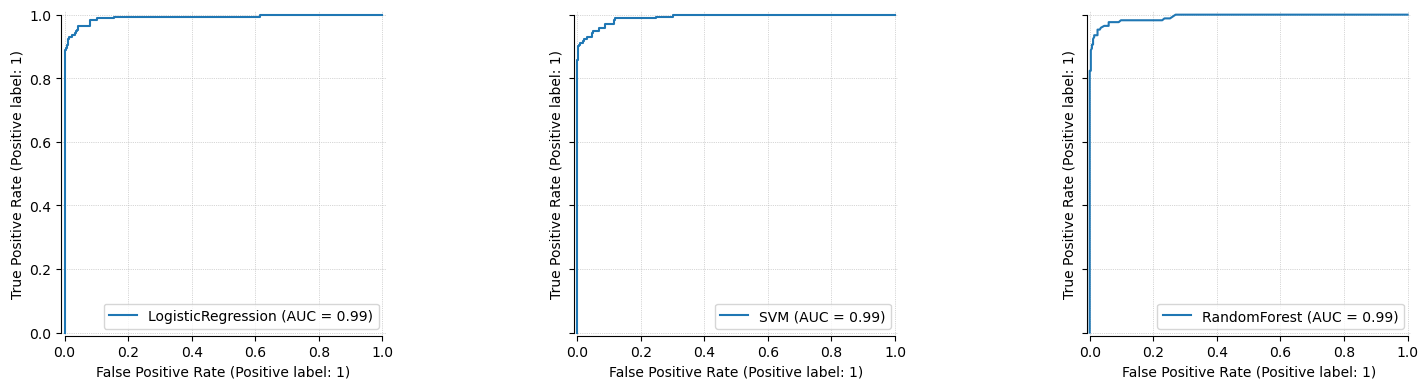

In [53]:
fig, axs = plt.subplots(figsize=(16,4), nrows=1, ncols=3, sharex=True, sharey=True)

RocCurveDisplay.from_predictions(y_train, logistic_scores, ax=axs[0], despine=True, name="LogisticRegression")
RocCurveDisplay.from_predictions(y_train, svm_scores,      ax=axs[1], despine=True, name="SVM")
RocCurveDisplay.from_predictions(y_train, forest_scores,   ax=axs[2], despine=True, name="RandomForest")

for ax in axs:
    ax.grid(True, linewidth=0.5, linestyle=":")
fig.tight_layout()

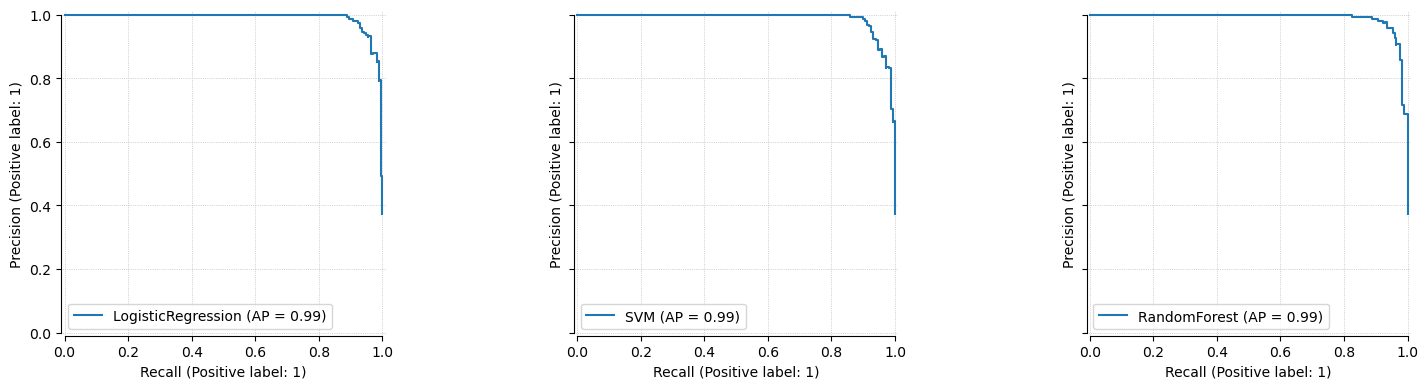

In [54]:
fig, axs = plt.subplots(figsize=(16,4), nrows=1, ncols=3, sharex=True, sharey=True)

PrecisionRecallDisplay.from_predictions(y_train, logistic_scores, ax=axs[0], despine=True, name="LogisticRegression")
PrecisionRecallDisplay.from_predictions(y_train, svm_scores,      ax=axs[1], despine=True, name="SVM")
PrecisionRecallDisplay.from_predictions(y_train, forest_scores,   ax=axs[2], despine=True, name="RandomForest")

for ax in axs:
    ax.grid(True, linewidth=0.5, linestyle=":")
fig.tight_layout()

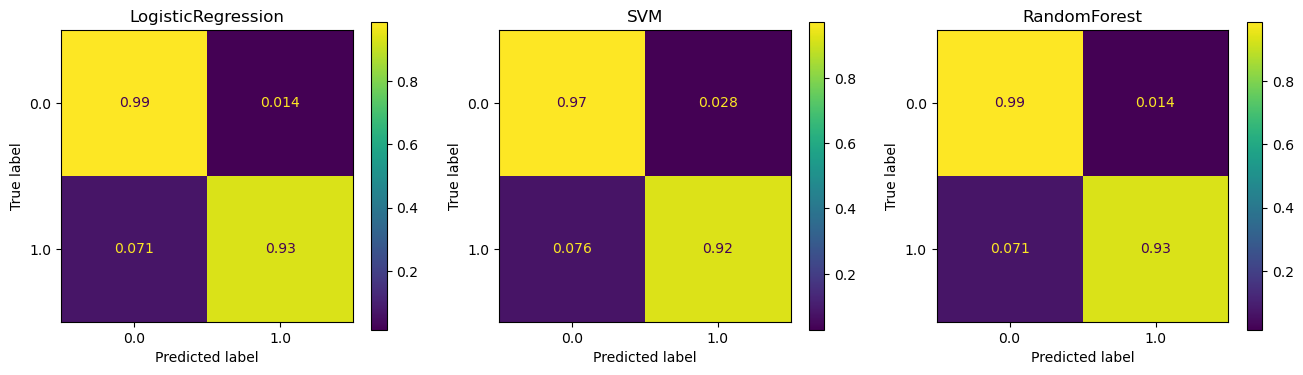

In [55]:
fig, axs = plt.subplots(figsize=(16,4), nrows=1, ncols=3, sharex=True, sharey=False)

ConfusionMatrixDisplay.from_predictions(y_train, y_pred_logistc, ax=axs[0], normalize="true")
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_svm,     ax=axs[1], normalize="true")
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_forest,  ax=axs[2], normalize="true")

for ax, title in zip(axs, ("LogisticRegression", "SVM", "RandomForest")):
    ax.set_title(title)

In [56]:
# Logistic Regression
report = classification_report(y_true=y_train, y_pred=y_pred_logistc)
print(report)

              precision    recall  f1-score   support

         0.0       0.96      0.99      0.97       285
         1.0       0.98      0.93      0.95       170

    accuracy                           0.96       455
   macro avg       0.97      0.96      0.96       455
weighted avg       0.97      0.96      0.96       455



In [57]:
# SVM
report = classification_report(y_true=y_train, y_pred=y_pred_svm)
print(report)

              precision    recall  f1-score   support

         0.0       0.96      0.97      0.96       285
         1.0       0.95      0.92      0.94       170

    accuracy                           0.95       455
   macro avg       0.95      0.95      0.95       455
weighted avg       0.95      0.95      0.95       455



In [58]:
# Forest
report = classification_report(y_true=y_train, y_pred=y_pred_forest)
print(report)

              precision    recall  f1-score   support

         0.0       0.96      0.99      0.97       285
         1.0       0.98      0.93      0.95       170

    accuracy                           0.96       455
   macro avg       0.97      0.96      0.96       455
weighted avg       0.97      0.96      0.96       455



# Hyperparameter tuning

In [59]:
cv = StratifiedKFold(n_splits=3, shuffle=True)

## Logistic Regression

In [60]:
logistic_reg

('logistic_regression',
 LogisticRegression(C=1, l1_ratio=1, max_iter=1000, solver='liblinear'))

In [61]:
logistic_param_distributions = {
    "logistic_regression__C" : np.logspace(-5, 5, 500),
    "logistic_regression__l1_ratio" : np.linspace(0, 1, 101),
    "logistic_regression__solver" : ["saga"],
    "logistic_regression__max_iter" : [10000, 15000, 20000, 25000]
}

In [62]:
logistic_pipe = Pipeline([
        ("transformer", transformer),
        ("scaler", StandardScaler()),
        logistic_reg
    ])
logistic_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function cal...t 0x17d61cf40>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictio

In [63]:
# use this to avoid ZeroDivision warning when calculating precision
scoring = {
    "f1": "f1",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "roc_auc": "roc_auc"
}

In [64]:
logistic_search = RandomizedSearchCV(
    logistic_pipe,
    param_distributions=logistic_param_distributions,
    n_iter=2000,
    cv=cv,
    scoring=scoring,
    error_score="raise",
    refit="f1"
)
logistic_search

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...liblinear'))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'logistic_regression__C': array([1.0000...00000000e+05]), 'logistic_regression__l1_ratio': array([0. , ... 0.99, 1. ]), 'logistic_regression__max_iter': [10000, 15000, ...], 'logistic_regression__solver': ['saga']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",2000
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","{'f1': 'f1', 'precision': make_scorer(p...ro_division=0), 'recall': 'recall', 'roc_auc': 'roc_auc'}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can

In [65]:
# final dataset used for training
# Since feature selection happends inside the Function transformer
# we use the complete dataset for training the final model
training_dataset = mlflow.data.from_pandas(
    pd.merge(X_train, y_train, left_index=True, right_index=True),
    name="X_train_for_randomized_search",
    targets="y_train"
)

In [66]:
logistic_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...liblinear'))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'logistic_regression__C': array([1.0000...00000000e+05]), 'logistic_regression__l1_ratio': array([0. , ... 0.99, 1. ]), 'logistic_regression__max_iter': [10000, 15000, ...], 'logistic_regression__solver': ['saga']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",2000
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","{'f1': 'f1', 'precision': make_scorer(p...ro_division=0), 'recall': 'recall', 'roc_auc': 'roc_auc'}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can

In [67]:
logistic_best_scores = pd.DataFrame(logistic_search.cv_results_)
logistic_best_scores

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_logistic_regression__solver,param_logistic_regression__max_iter,param_logistic_regression__l1_ratio,param_logistic_regression__C,params,split0_test_f1,...,split2_test_recall,mean_test_recall,std_test_recall,rank_test_recall,split0_test_roc_auc,split1_test_roc_auc,split2_test_roc_auc,mean_test_roc_auc,std_test_roc_auc,rank_test_roc_auc
0,0.003888,0.002917,0.003944,0.000352,saga,20000,0.50,0.000019,"{'logistic_regression__solver': 'saga', 'logis...",0.000000,...,0.000000,0.000000,0.000000,1480,0.500000,0.500000,0.500000,0.500000,0.000000,1501
1,0.001455,0.000028,0.003467,0.000074,saga,10000,0.55,0.000440,"{'logistic_regression__solver': 'saga', 'logis...",0.000000,...,0.000000,0.000000,0.000000,1480,0.500000,0.500000,0.500000,0.500000,0.000000,1501
2,0.001443,0.000013,0.003443,0.000064,saga,15000,0.77,0.000220,"{'logistic_regression__solver': 'saga', 'logis...",0.000000,...,0.000000,0.000000,0.000000,1480,0.500000,0.500000,0.500000,0.500000,0.000000,1501
3,0.015147,0.002720,0.003425,0.000055,saga,25000,0.45,12.364722,"{'logistic_regression__solver': 'saga', 'logis...",0.934579,...,1.000000,0.935673,0.050306,1,0.994645,0.992059,0.999248,0.995317,0.002973,195
4,0.033310,0.003203,0.003485,0.000020,saga,10000,0.63,272.188479,"{'logistic_regression__solver': 'saga', 'logis...",0.934579,...,1.000000,0.935673,0.050306,1,0.992982,0.991136,0.999248,0.994455,0.003472,514
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,0.001647,0.000006,0.003488,0.000008,saga,15000,0.10,0.002660,"{'logistic_regression__solver': 'saga', 'logis...",0.438356,...,0.178571,0.211571,0.048900,1442,0.990766,0.990766,0.993045,0.991526,0.001074,1285
1996,0.035780,0.003400,0.003536,0.000006,saga,25000,0.72,18134.978042,"{'logistic_regression__solver': 'saga', 'logis...",0.934579,...,1.000000,0.935673,0.050306,1,0.992798,0.990951,0.999248,0.994332,0.003557,700
1997,0.001699,0.000026,0.003504,0.000020,saga,25000,0.89,0.009246,"{'logistic_regression__solver': 'saga', 'logis...",0.000000,...,0.000000,0.011696,0.016541,1468,0.952539,0.925577,0.952068,0.943395,0.012600,1491
1998,0.001477,0.000031,0.003468,0.000013,saga,10000,0.15,0.000879,"{'logistic_regression__solver': 'saga', 'logis...",0.000000,...,0.000000,0.000000,0.000000,1480,0.500000,0.500000,0.500000,0.500000,0.000000,1501


In [68]:
idx = logistic_search.best_index_
logistic_best_score = logistic_best_scores.iloc[idx, :]
logistic_best_score

mean_fit_time                                                                   0.002876
std_fit_time                                                                    0.000326
mean_score_time                                                                 0.003434
std_score_time                                                                  0.000051
param_logistic_regression__solver                                                   saga
param_logistic_regression__max_iter                                                20000
param_logistic_regression__l1_ratio                                                 0.05
param_logistic_regression__C                                                    0.425852
params                                 {'logistic_regression__solver': 'saga', 'logis...
split0_test_f1                                                                  0.944444
split1_test_f1                                                                   0.93578
split2_test_f1       

In [69]:
logistic_params = logistic_best_score.loc["params"]
logistic_params

{'logistic_regression__solver': 'saga',
 'logistic_regression__max_iter': 20000,
 'logistic_regression__l1_ratio': np.float64(0.05),
 'logistic_regression__C': np.float64(0.42585182918434145)}

In [70]:
logistic_search.best_score_

np.float64(0.9571249011453608)

In [71]:
artifacts_dir = Path().cwd().parent / "src" / "artifacts" / "models"
artifacts_dir.exists()

True

In [72]:
_ = joblib.dump(logistic_search.best_estimator_, artifacts_dir.joinpath("logistic_regression.joblib"))

In [73]:
best_model = logistic_search.best_estimator_

In [74]:
logistic_search.best_params_

{'logistic_regression__solver': 'saga',
 'logistic_regression__max_iter': 20000,
 'logistic_regression__l1_ratio': np.float64(0.05),
 'logistic_regression__C': np.float64(0.42585182918434145)}

In [75]:
testing_dataset = mlflow.data.from_pandas(
    pd.merge(X_test, y_test, left_index=True, right_index=True),
    name="X_test_for_randomized_search",
    targets="y_test"
)

In [76]:
y_pred_test = best_model.predict(X_test)
y_pred_scores_test = best_model.predict_proba(X_test)[:,1]

In [77]:
# on test data
print(
    classification_report(y_pred=y_pred_test, y_true=y_test)
)

              precision    recall  f1-score   support

         0.0       0.96      1.00      0.98        72
         1.0       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



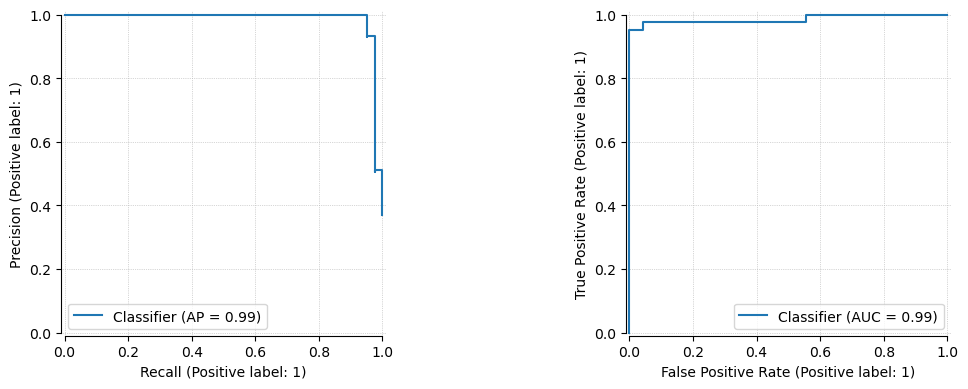

In [78]:
fig, axs = plt.subplots(figsize=(12,4), nrows=1, ncols=2)

PrecisionRecallDisplay.from_predictions(y_true=y_test, y_score=y_pred_scores_test, ax=axs[0], despine=True)
RocCurveDisplay.from_predictions(y_true=y_test, y_score=y_pred_scores_test, ax=axs[1], despine=True)

for ax in axs:
    ax.grid(True, linewidth=0.5, linestyle=":")
fig.tight_layout()

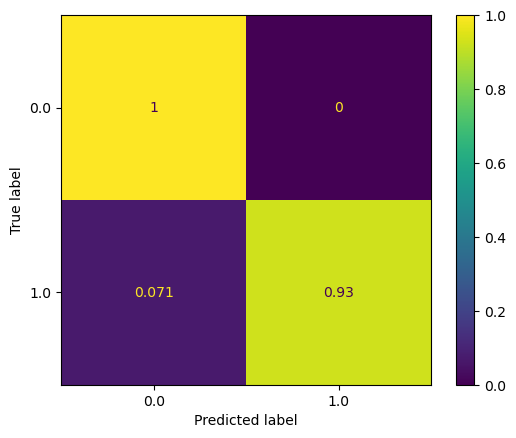

In [79]:
confusion_matrx_fig, cm_ax = plt.subplots()
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, normalize="true", ax=cm_ax)

In [80]:
with mlflow.start_run(run_name="Logistic_Regression_randomized_search"):

    # dataset used for final training
    mlflow.log_input(training_dataset, context="training")
    # dataset used for testing on unseen data
    mlflow.log_input(testing_dataset, context="testing")
    # log only the params of the logistic regression
    mlflow.log_params(best_model["logistic_regression"].get_params())
    # best metric after cross validation - selecting and refitting the model
    mlflow.log_metrics(
        {
            "best_f1_score"        : logistic_best_score["mean_test_f1"],
            "best_precision_score" : logistic_best_score["mean_test_precision"],
            "best_recall_score"    : logistic_best_score["mean_test_recall"],
            "best_roc_auc_score"   : logistic_best_score["mean_test_roc_auc"],
            "std_test_f1"          : logistic_best_score["std_test_f1"],
            "std_test_precision"   : logistic_best_score["std_test_precision"],
            "std_test_recall"      : logistic_best_score["std_test_recall"],
            "std_test_roc_auc"     : logistic_best_score["std_test_roc_auc"],
        }
    )
    
    # log the best model after refit
    signature = mlflow.models.infer_signature(X_train, logistic_search.best_estimator_.predict(X_train))
    mlflow.sklearn.log_model(
        sk_model=logistic_search.best_estimator_,
        name="logistic_regression",
        signature=signature,
        input_example=X_train.head(3),
        skops_trusted_types=["components.transformations.calculate_deviations"] # include all functions that affect the pipeline here
    )
    # Test metrics
    mlflow.log_metrics(
        {
            "test_f1_score"        : f1_score(y_true=y_test, y_pred=y_pred_test),
            "test_precision_score" : precision_score(y_true=y_test, y_pred=y_pred_test),
            "test_recall_score"    : recall_score(y_true=y_test, y_pred=y_pred_test),
            "test_roc_auc_score"   : roc_auc_score(y_true=y_test, y_score=y_pred_scores_test)
        }
    )
    # plots
    mlflow.log_figure(fig, "metrics/PrecisionRecallCurve_ROC_LR.png")
    mlflow.log_figure(confusion_matrx_fig, "metrics/ConfusionMatrix_LR.png")

🏃 View run Logistic_Regression_randomized_search at: http://127.0.0.1:5000/#/experiments/1/runs/ba8fc0a6f3404815a83cba7e38c41225
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


## Random Forest

In [81]:
forest

('forest', RandomForestClassifier(criterion='entropy'))

In [82]:
forest_param_distributions = {
    "forest__n_estimators" : np.arange(10, 1010, 10),
    "forest__criterion" : ["gini", "entropy"],
    "forest__max_depth" : np.arange(2,22,2),
    "forest__max_features" : [10, "sqrt", None]
}

In [83]:
forest_pipe = Pipeline([
    ("transformer", transformer),
    ("scaler", StandardScaler()),
    forest
])

In [84]:
forest_search = RandomizedSearchCV(
    forest_pipe,
    param_distributions=forest_param_distributions,
    n_iter=2000,
    cv=cv,
    scoring=scoring,
    error_score="raise",
    refit="f1"
)
forest_search

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...='entropy'))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'forest__criterion': ['gini', 'entropy'], 'forest__max_depth': array([ 2, 4..., 16, 18, 20]), 'forest__max_features': [10, 'sqrt', ...], 'forest__n_estimators': array([ 10, ... 1000])}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",2000
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","{'f1': 'f1', 'precision': make_scorer(p...ro_division=0), 'recall': 'recall', 'roc_auc': 'roc_auc'}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchange

In [85]:
forest_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...='entropy'))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'forest__criterion': ['gini', 'entropy'], 'forest__max_depth': array([ 2, 4..., 16, 18, 20]), 'forest__max_features': [10, 'sqrt', ...], 'forest__n_estimators': array([ 10, ... 1000])}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",2000
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","{'f1': 'f1', 'precision': make_scorer(p...ro_division=0), 'recall': 'recall', 'roc_auc': 'roc_auc'}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchange

In [86]:
forest_best_scores = pd.DataFrame(forest_search.cv_results_)
forest_best_scores

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_forest__n_estimators,param_forest__max_features,param_forest__max_depth,param_forest__criterion,params,split0_test_f1,...,split2_test_recall,mean_test_recall,std_test_recall,rank_test_recall,split0_test_roc_auc,split1_test_roc_auc,split2_test_roc_auc,mean_test_roc_auc,std_test_roc_auc,rank_test_roc_auc
0,0.062283,0.002308,0.011030,0.000097,190,sqrt,4,entropy,"{'forest__n_estimators': 190, 'forest__max_fea...",0.927273,...,0.910714,0.917607,0.022033,609,0.986704,0.996307,0.992481,0.991830,0.003947,204
1,0.324654,0.006009,0.031281,0.000230,750,10,10,gini,"{'forest__n_estimators': 750, 'forest__max_fea...",0.896552,...,0.910714,0.917607,0.008663,609,0.977655,0.993906,0.982143,0.984568,0.006853,1394
2,0.042236,0.001078,0.006735,0.000045,80,None,6,entropy,"{'forest__n_estimators': 80, 'forest__max_feat...",0.905983,...,0.910714,0.911759,0.014344,1512,0.972761,0.991413,0.991541,0.985238,0.008823,1234
3,0.273699,0.001759,0.038748,0.000164,920,sqrt,18,gini,"{'forest__n_estimators': 920, 'forest__max_fea...",0.927273,...,0.910714,0.917607,0.022033,609,0.985596,0.996122,0.990414,0.990710,0.004302,480
4,0.231662,0.003298,0.021385,0.000034,490,10,14,entropy,"{'forest__n_estimators': 490, 'forest__max_fea...",0.905983,...,0.910714,0.917607,0.008663,609,0.980332,0.991967,0.987594,0.986631,0.004798,1014
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,0.209302,0.004776,0.019984,0.000177,440,None,12,gini,"{'forest__n_estimators': 440, 'forest__max_fea...",0.896552,...,0.892857,0.911654,0.015098,1644,0.976916,0.993075,0.980639,0.983543,0.006909,1608
1996,0.105670,0.002070,0.011869,0.000072,220,10,6,entropy,"{'forest__n_estimators': 220, 'forest__max_fea...",0.905983,...,0.910714,0.917607,0.008663,609,0.979317,0.992244,0.990414,0.987325,0.005712,777
1997,0.413313,0.011656,0.038454,0.000970,950,10,10,gini,"{'forest__n_estimators': 950, 'forest__max_fea...",0.896552,...,0.910714,0.917607,0.008663,609,0.978393,0.993259,0.981955,0.984536,0.006338,1402
1998,0.096522,0.000498,0.015860,0.000112,320,sqrt,8,gini,"{'forest__n_estimators': 320, 'forest__max_fea...",0.927273,...,0.910714,0.917607,0.022033,609,0.988827,0.996307,0.991165,0.992100,0.003124,142


In [87]:
idx = forest_search.best_index_
forest_best_score = forest_best_scores.iloc[idx, :]
forest_best_score

mean_fit_time                                                          0.057697
std_fit_time                                                           0.000135
mean_score_time                                                        0.011003
std_score_time                                                         0.000022
param_forest__n_estimators                                                  190
param_forest__max_features                                                 sqrt
param_forest__max_depth                                                       6
param_forest__criterion                                                    gini
params                        {'forest__n_estimators': 190, 'forest__max_fea...
split0_test_f1                                                         0.936937
split1_test_f1                                                         0.964912
split2_test_f1                                                         0.962963
mean_test_f1                            

In [88]:
forest_params = forest_best_score.loc["params"]
forest_params

{'forest__n_estimators': np.int64(190),
 'forest__max_features': 'sqrt',
 'forest__max_depth': np.int64(6),
 'forest__criterion': 'gini'}

In [89]:
forest_search.best_score_

np.float64(0.9549373935338847)

In [90]:
_ = joblib.dump(forest_search.best_estimator_, artifacts_dir.joinpath("forest.joblib"))

In [91]:
best_forest = forest_search.best_estimator_

In [92]:
forest_search.best_params_

{'forest__n_estimators': np.int64(190),
 'forest__max_features': 'sqrt',
 'forest__max_depth': np.int64(6),
 'forest__criterion': 'gini'}

In [93]:
y_pred_forest_test = best_forest.predict(X_test)
y_pred_forest_scores_test = best_forest.predict_proba(X_test)[:,1]

In [94]:
# on test data
print(
    classification_report(y_pred=y_pred_forest_test, y_true=y_test)
)

              precision    recall  f1-score   support

         0.0       0.96      1.00      0.98        72
         1.0       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



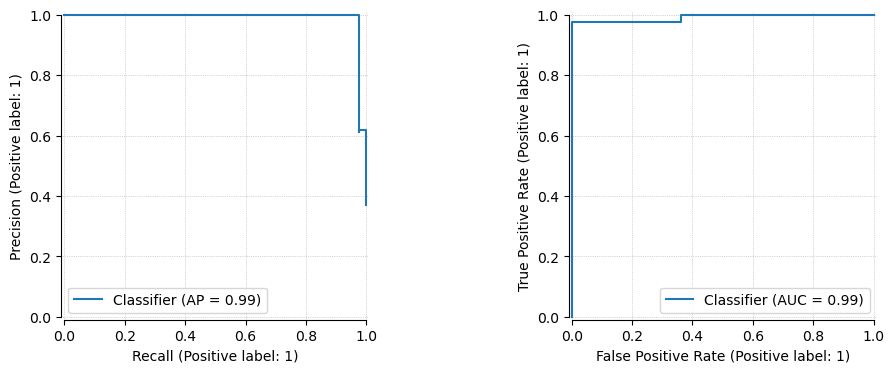

In [95]:
forest_curves_fig, forest_axs = plt.subplots(figsize=(12,4), nrows=1, ncols=2)

PrecisionRecallDisplay.from_predictions(y_true=y_test, y_score=y_pred_forest_scores_test, ax=forest_axs[0], despine=True)
RocCurveDisplay.from_predictions(y_true=y_test, y_score=y_pred_forest_scores_test, ax=forest_axs[1], despine=True)

for ax in forest_axs:
    ax.grid(True, linewidth=0.5, linestyle=":")
fig.tight_layout()

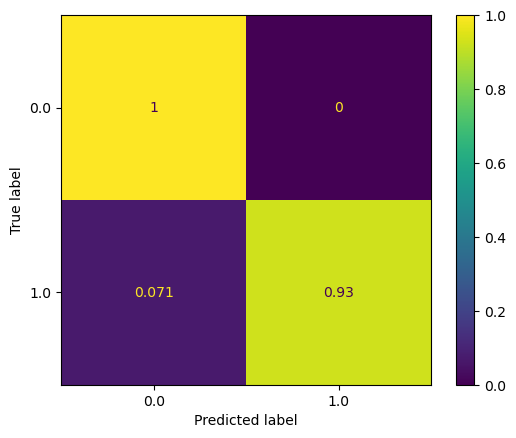

In [96]:
forest_cm_fig, forest_ax = plt.subplots()
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_forest_test, normalize="true", ax=forest_ax)

In [97]:
with mlflow.start_run(run_name="Random_Forest_randomized_search"):

    # dataset used for final training - same as for Logistic regression
    mlflow.log_input(training_dataset, context="training")
    # dataset used for testing on unseen data - same as for Logistic regression
    mlflow.log_input(testing_dataset, context="testing")
    # log only the params of the logistic regression
    mlflow.log_params(best_forest["forest"].get_params())
    # best metric after cross validation - selecting and refitting the model
    mlflow.log_metrics(
        {
            "best_f1_score"        : forest_best_score["mean_test_f1"],
            "best_precision_score" : forest_best_score["mean_test_precision"],
            "best_recall_score"    : forest_best_score["mean_test_recall"],
            "best_roc_auc_score"   : forest_best_score["mean_test_roc_auc"],
            "std_test_f1"          : forest_best_score["std_test_f1"],
            "std_test_precision"   : forest_best_score["std_test_precision"],
            "std_test_recall"      : forest_best_score["std_test_recall"],
            "std_test_roc_auc"     : forest_best_score["std_test_roc_auc"],
        }
    )
    
    # log the best model after refit
    signature = mlflow.models.infer_signature(X_train, best_forest.predict(X_train))
    mlflow.sklearn.log_model(
        sk_model=best_forest,
        name="random_forest",
        signature=signature,
        input_example=X_train.head(3),
        skops_trusted_types=["components.transformations.calculate_deviations", 'sklearn.tree._tree.Tree'] # include all functions that affect the pipeline here
    )
    # Test metrics
    mlflow.log_metrics(
        {
            "test_f1_score"        : f1_score(y_true=y_test, y_pred=y_pred_forest_test),
            "test_precision_score" : precision_score(y_true=y_test, y_pred=y_pred_forest_test),
            "test_recall_score"    : recall_score(y_true=y_test, y_pred=y_pred_forest_test),
            "test_roc_auc_score"   : roc_auc_score(y_true=y_test, y_score=y_pred_forest_scores_test)
        }
    )
    # plots
    mlflow.log_figure(forest_curves_fig, "metrics/PrecisionRecallCurve_ROC_RF.png")
    mlflow.log_figure(forest_cm_fig, "metrics/ConfusionMatrix_RF.png")

🏃 View run Random_Forest_randomized_search at: http://127.0.0.1:5000/#/experiments/1/runs/e4509d98c0f143999073a3a9e6900e05
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


# Coefficients

In [103]:
X_train_engineered.columns

Index(['texture_mean', 'area_mean', 'smoothness_mean', 'compactness_mean',
       'symmetry_mean', 'area_se', 'compactness_se',
       'texture_deviation_relative', 'area_deviation_relative',
       'smoothness_deviation_relative', 'compactness_deviation_relative',
       'symmetry_deviation_relative'],
      dtype='str')

In [104]:
best_model["logistic_regression"].coef_

array([[ 2.73675855,  1.08831873,  0.73376525,  0.35125517,  0.52048737,
         0.35633544,  0.43708183,  0.23665431,  0.9978489 ,  0.29140219,
         1.59144287, -0.13175957]])

In [112]:
coefficients = {feature:float(val) for feature, val in zip(X_train_engineered.columns.tolist(), best_model["logistic_regression"].coef_[0])}
coefficients

{'texture_mean': 2.736758551041369,
 'area_mean': 1.0883187281712932,
 'smoothness_mean': 0.733765251695202,
 'compactness_mean': 0.351255166677494,
 'symmetry_mean': 0.5204873656519046,
 'area_se': 0.35633543942908114,
 'compactness_se': 0.43708183195165684,
 'texture_deviation_relative': 0.23665431207625426,
 'area_deviation_relative': 0.9978488986927673,
 'smoothness_deviation_relative': 0.2914021864084899,
 'compactness_deviation_relative': 1.5914428651356018,
 'symmetry_deviation_relative': -0.1317595740983651}

In [113]:
best_model["logistic_regression"].intercept_

array([-0.33636006])